# Introducción a GeoPandas - Parte II
## Geoprocesamiento y análisis vectorial básico en Python

<div style="border-top: 3px solid #737373; margin: 10px 0;"></div>

**Autor:** Roberto Valiente, Universidad de Alcalá (roberto.valiente@uah.es) <br>
**Asignatura:** Programación en TIG | Master en Tecnologías de la Información Geográfica <br>
**Fecha:** Diciembre de 2025

<br>
<br>

En el tutorial anterior (GeoPandas Parte I), aprendimos a importar archivos shapefile, reproyectar capas, geocodificar información espacial y a crear cartografía básica usando las librerías <code>GeoPandas</code>, <code>GeoPy</code>, <code>Matplotlib</code>, <code>CartoPy</code> y <code>Contextily</code>. En este nuevo tutorial, vamos a profundizar un poco más en algunas herramientas de geoprocesamiento y análisis vectorial básico en Python. En concreto, vamos a practicar con operaciones de creación de buffers, intersecciones, disolución de entidades poligonales, cálculo de centroides, unión de capas, operaciones de unión espacial por localización (*spatial join*) y medición de distancias en línea recta.

Para ello, vamos a rescatar las bases de datos utilizadas y creadas en el tutorial anterior (GeoPandas I) para realizar un pequeño ejercicio:
- paises.shp. Capa shapefile con los polígonos de todos los países del mundo.
- ais_data.shp. Capa con información de posicionamiento de 10.000 barcos en noviembre de 2024.
- puertos.shp. Capa de información de los puertos con mayor tráfico de contenedores en el mundo en 2011.

Vamos a crear un nuevo proyecto para realizar este tutorial y a cargar todas las capas que necesitamos. Puedes elegir hacerlo en Spyder o en un Jupyter Notebook.

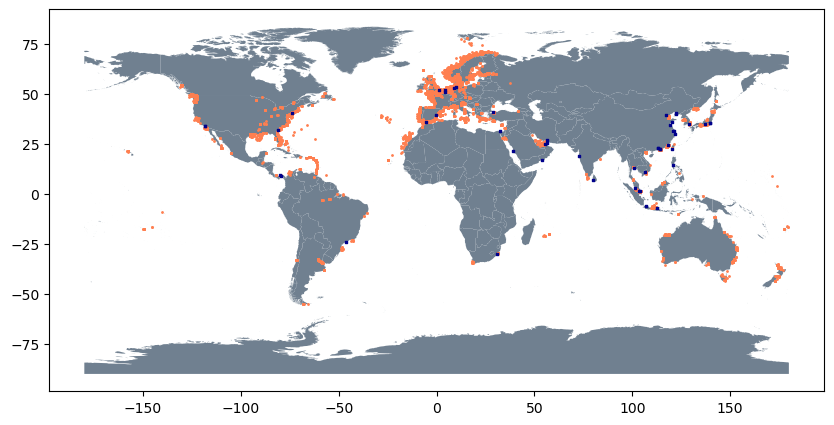

In [1]:
# Importamos las librerías que necesitamos
import geopandas as gpd
import matplotlib.pyplot as plt

# Cargando las capas
paises = gpd.read_file("data/datos/paises.shp")
barcos = gpd.read_file("output/ais_data.shp")
puertos = gpd.read_file("output/puertos.shp")

# Visualizando las capas
fig, ax = plt.subplots(figsize=(10, 6))
paises.plot(ax=ax, color="slategray", edgecolor=None)
barcos.plot(ax=ax, color="coral", markersize=1)
puertos.plot(ax=ax, color="darkblue", marker="s", markersize=3)
plt.show()

<br>

Una desventaja de trabajar con Python frente a un SIG de escritorio como ArcGIS o QGIS es que la visualización de de datos no es automática. Si trabajamos en Spyder, podemos ver cómo las capas se van añadiendo al menú "Explorador de variables". Pero si trabajamos con Jupyter ni siquiera tenemos esta opción disponible. Para visualizar todas las variables, objetos y funciones que tenemos actualmente en nuestro entorno Python nos ofrece una serie de **comandos mágicos**. Observa los siguientes códigos.

In [ ]:
%who # Lista las variables definidas en el entorno actual
%whos # Igual que who pero con más información
%dir # Lista los atributos y métodos de un objeto

<br>

Aprovechando nuestras capas, vamos a realizar un ejercicio para practicar con varias herramientas de geoprocesamiento, como uniones espaciales, cálculo de buffers, disolución de entidades poligonales, intersecciones o medición de distancias.

<br>
<br>

### 1. Analizando las posiciones de los barcos en el mundo

#### 1.1. Buffer: calculando las fronteras marítimas

En primer lugar, vamos a calcular un buffer de 200km alrededor de cada uno de nuestros países en un intento de identificar hasta donde llega la jurisdicción marítima de cada país y dónde empiezan las aguas internacionales.

Lo primero que debemos hacer siempre es comprobar el CRS en el que se encuentra nuestra capa de países para así saber las unidades de la misma.

In [3]:
# Comprobando el CRS de la capa de países:
paises.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<br>

Del comando anterior, vemos que la capa países está en el EPSG 4326 y que tiene coordenadas geográficas (latitud y longitud). Por ello, las unidades de la capa son grados (degree). Eso significa que si aplicamos el buffer directamente sobre esta capa, el algoritmo va a interpretar que las unidades son grados y cuando introduzcamos el parámetro de distancia interpretará "200 grados" en lugar de "200 metros". Para evitar este problema, necesitamos reproyectar la capa a un CRS con coordenadas proyectadas en metros. Vamos a usar el CRS proyectado de Mercator (EPSG 3857)

In [3]:
paises_mercator = paises.to_crs(epsg=3857)   # Web Mercator (EPSG válido)
paises_mercator.to_file("output/paises_mercator.shp") # Exportar el resultado para guardarlo
paises_mercator.info() # Comprobamos la información del archivo generado

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   admin     257 non-null    object  
 1   geometry  257 non-null    geometry
dtypes: geometry(1), object(1)
memory usage: 4.1+ KB


<br>

Para calcular el buffer, utilizaremos el método <code>buffer</code> de la librería <code>Shapely</code> integrado en GeoPandas. La siguiente tabla resume algunos argumentos que admite el método:

**Tabla 1**. Argumentos admitidos en el método buffer de Shapely.
| Argumento    | Descripción                                                                 |
|--------------|-----------------------------------------------------------------------------|
| distance     | Radio del buffer en las unidades del CRS (ej. metros si CRS proyectado).    |
| resolution   | Número de segmentos para aproximar un cuarto de círculo (por defecto 16). a menor resolución, polígonos más toscos.   |
| cap_style    | Forma de los extremos de buffers de líneas: 1 redondo, 2 plano, 3 cuadrado. |
| join_style   | Forma de las uniones en buffers de líneas: 1 redondo, 2 mitre, 3 bisel.     |
| mitre_limit  | Límite de la extensión de las esquinas cuando join_style=2 (mitre).         |

El único argumento obligatorio de entre los de la Tabla 1, es el de "distance". Para el resto se utilizan una serie de parámetros por defecto (resolution=16, cap_style=1, join_style=1, mitre_limit=5.0). Si quieres saber más sobre el método <cpde>buffer</code>, no dudes en consultar la [documentación de GeoPandas](https://geopandas.org/en/v1.1.0/docs/reference/api/geopandas.GeoSeries.buffer.html). La figura 1 muestra un ejemplo distinguiendo entre varios tipos de join_style.

<br>

**Figura 1**. Varios tipos de uniones en buffers (join_styles).
<p align="center">
  <img src="misc//join-styles-1.png" width="250">
</p>

*Fuente: [Paul Murrel, 2017, Variable-Width Line Ends and Line Joins](https://www.stat.auckland.ac.nz/~paul/Reports/VWline/line-styles/line-styles.html)*

Para calcular nuestros buffer utilizaremos los valores por defecto en todos los argumentos opcionales.

In [26]:
# Calcular buffer de 200 km (200.000 metros)
paises_buffer = paises_mercator.buffer(200000)

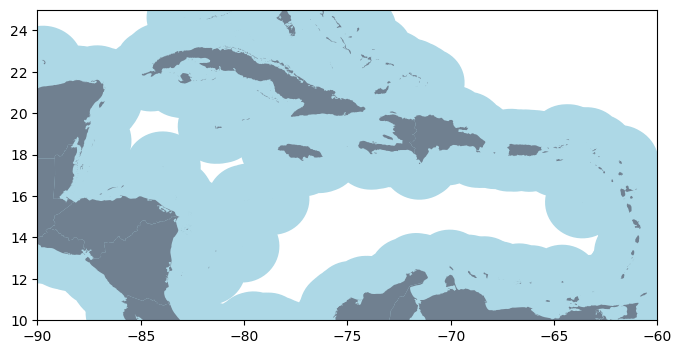

In [10]:
# Visualiza el resultado
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6)) # Crear figura y eje
paises_buffer.to_crs(epsg=4326).plot(ax=ax, color="lightblue", edgecolor=None)
paises_mercator.to_crs(epsg=4326).plot(ax=ax, color="slategray", edgecolor=None)

# Centrar visualización en el Caribe (aprox. límites en grados)
ax.set_xlim(-90, -60)   # longitudes
ax.set_ylim(10, 25)     # latitudes

plt.show()

En el código anterior, hemos incluido unas últimas líneas para visualizar el resultado y examinar que todo se hace bien. Hemos centrado la visualización en la zona del Caribe para ver cómo los buffers se calculan incluso sobre cada isla. Fíjate también que antes del método plot hemos pasado <code>.to_crs(epsg=3857)</code> para reproyectar las capas resultado al vuelo (cómo lo podríamos hacer en QGIS al cambiar el CRS del proyecto). Esto úlitmo lo hemos hecho sólo a modo de demostración. Podríamos elegir cualquier otro tipo de CRS.

Veamos la información y la tabla de atributos de nuestra capa buffer.

In [22]:
paises_buffer.info()

<class 'geopandas.geoseries.GeoSeries'>
RangeIndex: 257 entries, 0 to 256
Series name: None
Non-Null Count  Dtype   
--------------  -----   
257 non-null    geometry
dtypes: geometry(1)
memory usage: 2.1 KB


<br>

Al ejecutar el comando mágico <code>info()</code> vemos que el objeto creado es de tipo "geoseries". Es importante saber que un objeto "geoseries" no es un "geodataframe". Un objeto "geoseries" es básicamente una serie de geometrias (puntos, líneas o polígonos). Es similar a un objeto "serie" en Pandas. Sin embargo, a consecuencia de ello, un objeto "geoseries", a diferencia de un geodataframe, no tiene columnas adicionales de atributos, sólo el índice de la entidad y la geometría. Es por eso por lo que la columna "admin" con el nombre de los países en el shapefile "paises_mercator" original se ha perdido. Esta es una cuestión importante por que el método <code>buffer</code> nos devuelve siempre un objeto "geoseries".

Para solucionar este problema y convertir nuestra capa buffer en un geodataframe necesitaremos añadir la siguiente línea de codigo después de calcular nuestros buffers. Vamos a recalcular por tanto "paises_buffer" como un geodataframe utilizando la función <code>GeoDataFrame</code> y copiando (<code>.copy</code>) los atributos de la capa paises_mercator. Con el argumento <code>crs</code> establecemos el CRS de la capa de resultado.

In [27]:
import geopandas as gpd

# Crear buffer como GeoDataFrame, manteniendo atributos originales
gdf_paises_buffer = gpd.GeoDataFrame(
    paises_mercator.copy(), # atributos
    geometry=paises_buffer, # geometría
    crs=paises_mercator.crs # crs
)

gdf_paises_buffer.to_file("output/paises_buffer.shp") # Exportamos el resultado para guardarlo como .shp

# Si quieres hacer todo de una, aquí tienes la opción:
# paises_buffer = gpd.GeoDataFrame(
#     paises_mercator.copy(), 
#     geometry=paises_mercator.buffer(200000), 
#     crs=paises_mercator.crs
# )

In [29]:
# Comprobamos la información y la tabla de atributos de la capa:
gdf_paises_buffer.info() # Debería aparecer el nombre de los paises (admin)

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   admin     257 non-null    object  
 1   geometry  257 non-null    geometry
dtypes: geometry(1), object(1)
memory usage: 4.1+ KB


<br>
<br>

#### 1.2. Unión espacial e Intersección: identificando barcos en aguas internacionales

A continuación, vamos a utilizar nuestro buffer de 200km para identificar la posición de los barcos respecto la jurisdicción marítima de cada país. Para este proceso vamos a utilizar (y confrontar) dos herramientas: unión espacial (*spatial join* o unión de atributos por localización en QGIS) e intersección. Como sabéis, la herramienta de unión espacial nos va a decir dentro del buffer de qué país se encuentra cada barco. Con la herramienta de intersección podemos realizar un ejercicio parecido aunque sin traspaso de atributos: se creará una nueva capa con sólo los barcos que estén dentro de algún buffer (y por tanto, no en aguas internacionales). Para conseguir el resultado contrario a la capa de intersección e identificar los barcos que están fuera de los buffers podemos usar el método <code>difference</code>. Este comando es análogo al "clip" o "cortar" de QGIS o ArcGIS.

Vamos a poner en práctica todas estas ideas. Comenzamos con la unión espacial. Observa el siguiente fragmento de código.

In [35]:
import geopandas as gpd

# Preparando la unión espacial - reproyectando capas necesarias
barcos_reproj = barcos.to_crs(epsg=3857)

# Unión espacial
barcos_join = gpd.sjoin(barcos_reproj, gdf_paises_buffer, how="left", predicate="intersects")

# Resultado: cada barco con atributos del país cuyo buffer lo contiene
print("Previsualizar tabla de atributos:")
print(barcos_join.head())
print("Ver información de la capa:")
print(barcos_join.info())

Previsualizar tabla de atributos:
        MMSI                   TSTAMP  LATITUDE  LONGITUDE    COG  SOG  \
0  257465900  2024-11-19 20:28:06 GMT  63.43565   10.39761  137.6  0.0   
0  257465900  2024-11-19 20:28:06 GMT  63.43565   10.39761  137.6  0.0   
1  244850687  2024-11-19 20:28:09 GMT  52.54997    4.80413  360.0  0.0   
1  244850687  2024-11-19 20:28:09 GMT  52.54997    4.80413  360.0  0.0   
1  244850687  2024-11-19 20:28:09 GMT  52.54997    4.80413  360.0  0.0   

   HEADING  NAVSTAT IMO          NAME  ...   A   B  C  D DRAUGHT       DEST  \
0      511       15   0  D/S HANSTEEN  ...  20  10  3  2     0.0       None   
0      511       15   0  D/S HANSTEEN  ...  20  10  3  2     0.0       None   
1      511        5   0    WILHELMINA  ...  47  13  8  0     0.0  STARNMEER   
1      511        5   0    WILHELMINA  ...  47  13  8  0     0.0  STARNMEER   
1      511        5   0    WILHELMINA  ...  47  13  8  0     0.0  STARNMEER   

           ETA                         geometr

<br>

Debemos tener en cuenta que para que la unión espacial funcione, el método <code>sjoin</code> sólo admite como capas de entrada objetos "geodataframe". Por lo que antes de realizar cualquier unión, debemos confirmar que hicimos el paso anterior de convertir los buffers de "geoseries" a "geodataframe".

En la visualización de los resultados vemos que muchos de nuestros puntos se han duplicado. Si recordamos, nuestra base de datos inicial contaba con 10.000 barcos, pero ahora ésta cuenta con 19.414 entradas. Esto es porque por defecto <code>sjoin</code> realiza una unión de "uno a muchos" - y sólo permite esta opción. Así, nuestro barco en el índice 0, con ID MMSI "257465900" y de nombre "D/S HANSTEEN" se encuentra dentro de los buffers de Noruega y de Suecia. Esto ocurre por la manera que hemos hecho los buffers. La figura 2 muestra un ejemplo del problema en el Caribe: la zona marítima de las Bahamas (en rojo) solapa con la de Estados Unidos, Cuba y otros países caribeños.

<br>

**Figura 2**. Ejemplo de solapamiento de buffers en el caribe.
<p align="center">
  <img src="misc//bahamas_problem.png" width="400">
</p>

*Fuente: Visualización propia en QGIS*

<br>

Al igual que cuando hacemos un merge de datos tabulares con Pandas, en la unión espacial es posible elegir el tipo de unión que queremos realizar con un argumento <code>how</code>. La tabla 2 resume los posibles argumentos que admite <code>sjoin</code> en GeoPandas para personalizar nuestras operaciones de unión espacial o *spatial join*. Igualmente, te recomiendo visitar la [documentación de esta herramienta en la página de GeoPandas](https://geopandas.org/en/stable/docs/reference/api/geopandas.sjoin.html).

**Tabla 2**. Argumentos válidos en geopandas.sjoin.
| Argumento   | Valores posibles                                      | Descripción                                                                 |
|-------------|-------------------------------------------------------|-----------------------------------------------------------------------------|
| left_df     | GeoDataFrame - nuestro "barcos_reproj"                                         | Capa de entrada (ej. barcos).                                               |
| right_df    | GeoDataFrame - nuestro "gdf_paises_buffer"                                         | Capa de unión (ej. buffers).                                                |
| how         | "left" \| "right" \| "inner"                          | Tipo de unión:<br>• **left**: mantiene todos los elementos de la capa izquierda.<br>• **right**: mantiene todos los elementos de la capa derecha.<br>• **inner**: solo elementos que cumplen la condición espacial. |
| predicate   | "intersects" \| "contains" \| "within" \| "touches" \| "crosses" \| "overlaps" \| "covers" \| "covered_by" | Relación espacial usada para comparar geometrías. Ejemplos:<br>• **intersects**: cualquier solapamiento.<br>• **contains**: la geometría derecha contiene a la izquierda.<br>• **within**: la geometría izquierda está dentro de la derecha. |
| lsuffix     | string (por defecto "_left")                          | Sufijo para columnas duplicadas de la capa izquierda.                       |
| rsuffix     | string (por defecto "_right")                         | Sufijo para columnas duplicadas de la capa derecha.                         |
| distance    | float (opcional)                                      | Usado con predicados de proximidad (ej. "dwithin").                         |
| on_attribute| string o lista de strings (opcional)                  | Permite unir basándose en atributos además de la relación espacial.         |


Como verás, uno de los argumentos más importantes es el de predicado espacial <code>predicate</code>, que permite elegir la relación topológica para comparar las geometrias de entrada.

Con el resultado de nuestra unión espacial es posible ver qué barcos están en aguas internacionales y que por tanto no caen dentro de ningún buffer. Estos barcos tendrán valores NA en la columna "admin" que contiene el nombre de los países. El siguiente comando nos cuenta que hay un total de 28 barcos en aguas internacionales

In [37]:
barcos_join.isna().sum()

MMSI              0
TSTAMP            0
LATITUDE          0
LONGITUDE         0
COG               0
SOG               0
HEADING           0
NAVSTAT           0
IMO              54
NAME             66
CALLSIGN       1780
TYPE             54
A                54
B                54
C                54
D                54
DRAUGHT           0
DEST           7186
ETA               0
geometry          0
index_right      28
admin            28
dtype: int64

<br>

Sabiendo esto, es muy fácil filtrar la base de datos por la columna "admin" para extraer sólo los barcos que están en aguas internacionales al igual que hacíamos con cualquier base de datos tabular en Pandas. No obstante, para ensayar con otras herramientas de geoprocesamiento vectorial vamos a realizar operaciones de intersección y diferencia con los métodos <code>geopandas.intersects</code> y <code>geopandas.difference</code> para crear capas de barcos que están dentro de alguna jurisdicción marítima y barcos que estén en aguas internacionales, respectivamente.

Antes de utilizar estas herramientas vamos a realizar un paso intermedio. Como hemos visto antes, el shapefile de buffers contiene múltiples entidades (un buffer para cada país) que ademas se solapan entre ellas. Esta cuestión puede complicar un poco el desarrollo de las operaciones de intersección y diferencia. para hacer más fácil el análisis vamos a realizar primero una operación con el método <code>disolve</code> para disolver todas las entidades de la capa de buffer. Observa el siguiente código.

In [39]:
# Dissolve todos los buffers en una sola geometría
paises_buffers_dis = gdf_paises_buffer.dissolve()
paises_buffers_dis.to_file("output/paises_buffers_dis.shp") # Exportamos el resultado para guardarlo como .shp

<br>

Fíjate que en la operación de <code>disolve</code> hemos pasado "gdf_paises_buffer" que es la verión de "paises_buffer" convertido a "geodataframe". Esto es por que <code>disolve</code> sólo permite geodataframes como capas de entrada (no "geoseries"). Como resultado, la operación también nos devuelve un geodataframe.

Utilizando esta capa con entidades disueltas, ya estamos en buena posición para ejecutar los procesos de intersección y diferencia.

In [44]:
# Intersección - Filtrar barcos que intersectan con algún buffer
barcos_intersect = barcos_reproj[barcos_reproj.intersects(paises_buffers_dis.geometry.iloc[0])]
barcos_intersect.to_file("output/barcos_intersect.shp") # Exportamos el resultado para guardarlo como .shp

print(barcos_intersect.head())

        MMSI                   TSTAMP  LATITUDE  LONGITUDE    COG  SOG  \
0  257465900  2024-11-19 20:28:06 GMT  63.43565   10.39761  137.6  0.0   
1  244850687  2024-11-19 20:28:09 GMT  52.54997    4.80413  360.0  0.0   
2  577482000  2024-11-19 20:29:47 GMT  29.64671  -91.10542  130.1  0.0   
3  241799000  2024-11-19 20:28:23 GMT  37.91853   23.56585  295.0  0.0   
4  232025045  2024-11-19 20:25:40 GMT  18.03332  -63.09675  201.6  0.1   

   HEADING  NAVSTAT      IMO              NAME CALLSIGN TYPE   A   B   C  D  \
0      511       15        0      D/S HANSTEEN     LDQF   60  20  10   3  2   
1      511        5        0        WILHELMINA   PA5808    0  47  13   8  0   
2       26        5  9315513  NFE CLEAN ENERGY    YJWY4   70  11  60  13  4   
3      195        1  9310393      SEAVEN PRIDE    SVDP5   80  81  24  11  6   
4      511       15        0         LET IT BE    MGIH9   37   0   0   0  0   

   DRAUGHT            DEST          ETA                           geometry  
0  

<br>

La sintaxis es en realidad muy sencilla. La operación de intersección realiza un filtrado de la capa de entrada en esencia. Es por eso por lo que en la sintaxis verás <code> barcos_reproj[barcos_reproj.intersects()</code>. Eso significa que como paso previo a la intersección, Python primero crea una serie booleana (True/False) que identifica si las entidades en "barcos_reproj" cumplen la condición de intersectar con "paises_buffers_dis". Recordaras que las operaciones de filtrado en Pandas siempre utilizan corchetes ("[ ]").

También debes prestar atención a <code>.iloc[0]</code>. Esta parte del código es indispensable cuando hacemos una intersección. Básicamente, el comando <code>.iloc[0]</code> le dice a Python la entidad específica sobre la cual queremos hacer la intersección. Si omitimos esta parte, es bastante probable que Python nos devuelva un shapefile vacío. Es por eso también que la operación de disolver los polígonos de nuestra capa de buffer es una buena práctica. En QGIS o ArcGIS, el algoritmo de intersección automáticamente considera todas las entidades de la capa de entrada, pero en Python esto funciona distinto y debemos indicar qué entidades (polígonos en nuestro caso) de la capa de entrada "participan" en la intersección. En nuestro ejemplo, interpelamos a la entidad 0, que es el polígono disuelto de todos los buffers de zonas marítimas de cada país. Es cierto que el proceso en Python puede ser más tedioso que en un software SIG de escritorio, pero también esto nos da mucha más flexibilidad.

Como resultado, la intersección nos da también un objeto de tipo "geodataframe". La capa "barcos_intsersect.shp" nos ha devuelto una capa 9.972 barcos (puedes comprobarlo usando <code>info()</code>) que se encuentran dentro de la jurisdicción marítima de algún país del mundo. A diferencia de la unión espacial, aquí no hay valores duplicados pero perdemos la información directa de en qué país o países se encuentra cada barco.

A continuación, vamos a hacer la operación inversa: calcular la diferencia entre la capa de barcos y la capa de buffer para extraer los 28 barcos que hemos detectado en aguas internacionales. Observa el siguiente código.

In [49]:
# Diferencia entre barcos (puntos) y zonas marítimas de cada país (buffers)
geom_union = paises_buffers_dis.geometry.iloc[0] # Extraer la geometría única del dissolve

barcos_diff = barcos_reproj.geometry.difference(geom_union) # Calcular la diferencia: puntos fuera de los buffers

# Convertir a GeoDataFrame para mantener atributos
barcos_int = gpd.GeoDataFrame(barcos_reproj.copy(),
                              geometry=barcos_diff,
                              crs=barcos_reproj.crs)

# Filtrar: eliminar geometrías vacías
barcos_int = barcos_int[~barcos_int.is_empty & barcos_int.geometry.notna()]

barcos_int.to_file("output/barcos_int.shp") # Exportamos el resultado para guardarlo como .shp

C:\Users\ROBERTO\AppData\Local\Temp\ipykernel_19316\1798643789.py:12: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  barcos_int = barcos_int[~barcos_int.is_empty & barcos_int.geometry.notna()]


<br>

El código anterior es un poco diferente a la sintaxis ofrecida anteriormente al calcular la diferencia entre los buffers de 100 y 200 km. Esto ocurre porque en este caso estamos enfrentando capas de información con geometrías y tamaños diferentes: tenemos una capa de puntos y otra de líneas que tienen distinto número de entidades. En este caso, hemos utilizado <code>iloc[]</code> para seleccionar la entidad que vamos a utilizar en la capa de buffer (que es de entidad única tras hacer la disolución). <code>geometry.difference()</code> es lo mismo que <code>difference()</code> en términos prácticos, aunque técnicamente <code>geometry</code> se usa para llamar a "geoseries" mientras que <code>difference()</code> sirve para llamar específicamente a la columna de geometría dentro de un "geodataframe". Utilizamos el método <code>GeoDataFrame</code> para pasar el resultado a un geodataframe y combinar la geometría de resultado con los atributos de la capa de barcos. La capa de resultado de la conversión a geodataframe es una capa que tiene los 10.000 puntos, donde sólo aquellos que no caen dentro del buffer tiene geometría válida. No se van a representar en un mapa, pero en la tabla, siguen estando. Por ello, es necesario filtrar los datos para eliminar aquellos que tengan geometrías vacias. Finalmente, el código exporta la capa resultado a shapefile.

En definitiva, hay muchas maneras de identificar los barcos que están en aguas internacionales, como has visto.

<br>
<br>

#### 1.3. Cálculo de distancias: llevando cada barco a su puerto más cercano

Para continuar nuestro ejercicio vamos a calcular la distancia de cada uno de los barcos que están en aguas internacionales ("barcos_int.shp") a cada uno de los puertos más importantes del mundo ("puertos.shp"). Esta tarea se resolverá calculando una matriz de distancias que configuraremos con el método <code>distance</code> de GeoPandas y un bucle de repetición <code>for</code> que recorrerá todas las entidades de cada una de las bases de datos. en total tenemos 28 barcos en aguas internacionales desde los cuales calcularemos la distancia de cada uno de ellos a los 50 puertos más importantes del mundo.

Observa cómo funciona el siguiente código para resolver esta tarea. Lo primero que debemos hacer es asegurarnos que todas las capas comparten el mismo CRS.

In [57]:
import pandas as pd

# Reproyectamos los puertos a Web Mercator
puertos_reproj = puertos.to_crs(epsg=3857)

# Crear matriz de distancias
matriz = pd.DataFrame(
    [[b.distance(p) for p in puertos_reproj.geometry] for b in barcos_int.geometry],
    index=barcos_int.index, # Esto serán las filas
    columns=puertos_reproj.index # Esto serán las columnas
)

#Visualizar
print(matriz.head())

# Exportar a CSV
matriz.to_csv("output/matriz_distancias.csv", sep=";", index=True) 

                0             1             2             3             4   \
557   1.611696e+07  1.423890e+07  1.524104e+07  1.522974e+07  1.701359e+07   
783   2.371606e+07  2.195558e+07  2.290492e+07  2.289205e+07  2.457913e+07   
2067  2.090658e+07  1.935456e+07  2.015019e+07  2.013569e+07  2.174811e+07   
2254  1.416539e+07  1.541133e+07  1.431625e+07  1.428514e+07  1.451448e+07   
2447  2.045873e+07  1.873999e+07  1.965003e+07  1.963697e+07  2.132342e+07   

                5             6             7             8             9   \
557   1.615989e+07  1.514316e+07  1.606789e+07  8.699044e+06  5.493872e+06   
783   2.377179e+07  2.280190e+07  2.361751e+07  1.633413e+07  1.128970e+07   
2067  2.097065e+07  2.004208e+07  2.078063e+07  1.357994e+07  8.314645e+06   
2254  1.433110e+07  1.417253e+07  1.366629e+07  1.041760e+07  6.256629e+06   
2447  2.051425e+07  1.954642e+07  2.036271e+07  1.307808e+07  8.257315e+06   

      ...            40            41            42           

<br>

Específicamente, el bucle <code>for</code> anterior toma cada entidad en las capas de barcos (b) y puertos (p) y calcula su distancia en linea recta utilizando las columnas de geometría <code>.geometry</code> de cada base de datos. El resutlado se presenta en metros, que son las unidades en las que se dibujan las capas de barcos y puertos (puedes comprobarlo con <code>info()</code>). Para más información, también puedes visitar la documentación específica de GeoPandas para el método [distance](https://geopandas.org/en/latest/docs/reference/api/geopandas.GeoSeries.distance.html).

La matriz se representa mediante un dataframe, por eso hemos importado Pandas. Si queremos pasar los valores de la matriz a kilómetros, bastará con dividir todos los valores por 1.000. Como las variables de nuestro dataframe matriz son todas numéricas, podemos simplemente dividir toda la tabla entre 1.000.


In [58]:
# Convertir a kilómetros
matriz_km = matriz / 1000

# Exportar a CSV con separador punto y coma
matriz_km.to_csv("output/matriz_distancias_km.csv", sep=";", index=True)

print(matriz_km.head())

                0             1             2             3             4   \
557   16116.963185  14238.901001  15241.036667  15229.740642  17013.591624   
783   23716.061102  21955.581561  22904.919597  22892.053887  24579.133422   
2067  20906.576379  19354.562155  20150.187519  20135.688160  21748.114922   
2254  14165.385679  15411.325395  14316.254668  14285.137397  14514.478244   
2447  20458.728235  18739.993552  19650.027622  19636.969730  21323.422316   

                5             6             7             8             9   \
557   16159.893435  15143.159228  16067.888545   8699.044325   5493.871903   
783   23771.786132  22801.896863  23617.506448  16334.128469  11289.699353   
2067  20970.648852  20042.079943  20780.633057  13579.939813   8314.644671   
2254  14331.101370  14172.529731  13666.285597  10417.604884   6256.629454   
2447  20514.253041  19546.420369  20362.707761  13078.082301   8257.314538   

      ...            40            41            42           

<br>

Configurada nuestra matriz de distancias, ahora podemos filtrar el menor valor de entre las columnas (puertos) para cada fila (barco). Esto lo podemos manejar con Pandas usando la función <code>min</code>.

No obstante, GeoPandas ofrece un método más directo que nos devuleve directamente la distancia más cercana entre dos puntos: <code>.sjoin_nearest</code>. Este método funciona de forma similar al algoritmo "near" de QGIS o ArcGIS. Te recomiendo visitar su [documentación específica en la página de GeoPandas](https://geopandas.org/en/latest/docs/reference/api/geopandas.sjoin_nearest.html). Observa cómo funciona en el siguiente código.

In [64]:
# Calcular puerto más cercano para cada barco con sjoin
barcos_nearest = gpd.sjoin_nearest(
    barcos_int, puertos_reproj, how="left", distance_col="dist_min_km"
)

# Convertir a km si está en metros
barcos_nearest["dist_min_km"] = barcos_nearest["dist_min_km"] / 1000

print(barcos_nearest[["Puerto", "dist_min_km"]].head(28)) #Imprimimos el nombre del puerto en puertos_reporj y la distancia

                       Puerto  dist_min_km
557                 Algeciras  2859.406693
783                  Savannah  1319.703424
2067  Nueva York/Nueva Jersey  1202.976243
2254                 Hamburgo  5788.546132
2447                 Savannah  2177.636044
2883                 Savannah  1364.264929
3229                Algeciras  1891.309034
4209                 Hamburgo  4665.359437
4562                 Savannah  1183.899196
4595                Algeciras  1906.029711
4782                 Hamburgo  4342.196883
5156                 Hamburgo  4498.930686
5463                 Hamburgo  5881.302341
5780                   Balboa  2592.596227
6021                Algeciras  2112.267953
6393                 Savannah   895.907605
6735  Nueva York/Nueva Jersey  1224.331393
6814                Algeciras  1883.911505
7384                 Savannah   921.437425
7812                 Savannah  1187.688117
8147                 Savannah  1260.620255
8469                 Hamburgo  6034.350678
9015       

<br>

El resultado es un nuevo geodataframe. Para combinar toda la información, vamos a unir este nuevo geodataframe con sus distancias al puerto más cercano con el dataframe original de barcos en aguas internacionales para tener toda la información en una misma capa. Debemos recordar que <code>sjoin_nearest</code> usa el índice de fila para identificar cada barco, por lo que los resultados de barcos_nearest, se presentan en el mismo orden que los de la capa de entrada "barcos_int". Por ello, podemos usar el método <code>join</code>.

In [ ]:
# Unir por índice
barcos_int = barcos_int.join(
    barcos_nearest[["dist_min_km", "Puerto"]]
)

In [66]:
print(barcos_int.head())

           MMSI                   TSTAMP  LATITUDE  LONGITUDE    COG   SOG  \
557   228095780  2024-11-19 20:29:49 GMT  19.39744  -22.71501  221.7   4.8   
783   636016315  2024-11-19 20:10:04 GMT  27.18696  -91.52456  301.2  12.5   
2067  636021569  2024-11-19 20:09:19 GMT  34.72927  -66.29063  305.7  11.5   
2254  258874000  2024-11-19 20:28:46 GMT  74.40325   23.33518   42.7   3.3   
2447  368207150  2024-11-19 20:11:00 GMT  27.47600  -62.26333  130.0   6.7   

      HEADING  NAVSTAT      IMO       NAME  ...    A   B   C   D DRAUGHT  \
557       511       15        0   HOME ONE  ...    8   4   2   2     0.0   
783       303        0  9425497  PATRICK C  ...  150  34  17  10    10.9   
2067      305        0  9914632  MYKLEBUST  ...  143  37   7  22     7.3   
2254       41        7  9652818    ISHAVET  ...   25  49   7   8     7.6   
2447      511       15        0    CALYPSO  ...    9   6   6   2     0.0   

                DEST          ETA                           geometry  \
55

<br>
<br>

<div style="border: 2px solid #5bc0de; background-color: #d9edf7; padding: 10px; border-radius: 5px;">
  <strong>Ejercicio: Practicando el cálculo de distancias en línea recta</strong> <br>
    Una de los mayores benecifios de llevar un sistema GPS integrado en tu barco es el de poder saber qué otros barcos están cerca de tí y pueden socorrerte en caso de una emergencia. <br>
    Usa nuestra capa de "barcos" para calcular las parejas de barcos que están más cerca entre sí, considerando la distancia en línea recta, y utilizando las herramientas que has aprendido con GeoPandas.
</div>

<br>

<br>
<br>

### 2. Otras operaciones de geoprocesamiento vectorial

#### 2.1. Cálculo de centroides

El cálculo de centroides es una operación muy frecuente cuando trabajamos con SIG. Nos puede servir parar elaborar cartografía (por ejemplo cuando tenemos una variable cuantitativa absoluta en un shapefile poligonal y queremos representarla, recuerda que este tipo de variables se representan siempre con símbolos proporcionales), calcular distancias desde un punto genérico de un polígono, extraer valores medios de un ráster dentro de una entidad poligonal, etc. Con GeoPandas calcular el centroide de una capa de polígonos es bastante sencillo porque cada geometría en Python tiene un método <code>.centroid</code>. 

Imagina que queremos calcular el centroide de cada uno de nuestros países en el mundo. Vamos a utilizar la capa "paises_mercator" para ver cómo funciona esta herramienta.

In [3]:
import geopandas as gpd

paises_mercator = gpd.read_file("output/paises_mercator.shp") # Si no la tenemos, no olvides cargar la capa

# Crear una nueva capa con los centroides como geometría principal
centroides = paises_mercator.copy()
centroides.set_geometry(paises_mercator.geometry.centroid, inplace=True)

# Guardar la nueva capa
centroides.to_file("output/centroides.shp")

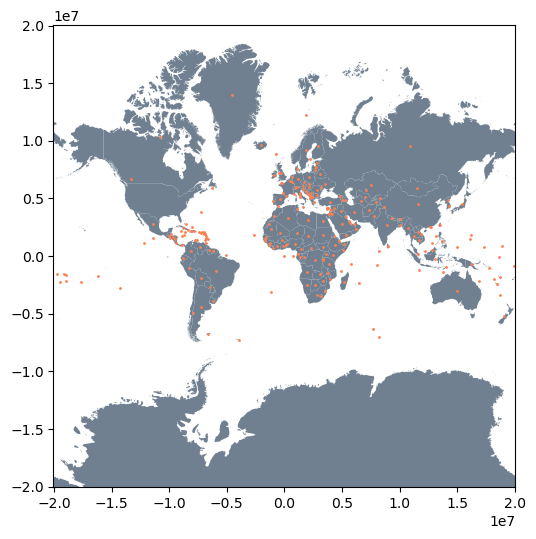

In [7]:
# Visualizando el resultado
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
paises_mercator.plot(ax=ax, color="slategray", edgecolor=None)
centroides.plot(ax=ax, color="coral", markersize=1)
# Límites en EPSG:3857 (metros)
ax.set_xlim(-20037508, 20037508)   # eje X
ax.set_ylim(-20037508, 20037508)   # eje Y
plt.show()

El código anterior usa "paises_mercator" para calcular los centroides de cada entidad poligonal dentro de la capa. Observa que la lógica de GeoPandas es la de simplemente cambiar la geometría de la capa de origen. Para ello, primero es necesario realizar una copia de la capa si lo que queremos es generar una nueva capa puntual con los centroides. Recuerda el problema de "aliasing". Si no hacemos esta copia, alteraremos directamente la capa origen de los datos. Una vez hecha la copia, utilizamos <code>set_geometry</code> para cambiar la geometría de la capa copiada y el método <code>.geometry.centroid()</code> para calcular los centroides y establecerlos como nueva geometría. El comando <code>inplace=True</code> le dice  Python que queremos que la operación se aplique directamente sobre el objeto, modificándolo en el sitio, en lugar de devolver una copia modificada del mismo. Este último argumento es opcional en nuestro caso, dado que hemos hecho una copia de nuestra capa original "paises_mercator".

Observa el resultado. El extracto de código anterior nos ha devuelto los centroides de cada entidad. Sin embargo, como bien saber, los centroides no siempre caen necesariamente dentro de los poligonos. Por ejemplo, la entidad "Estados Unidos" es un polígono multiparte con polígonos separados para representar Alaska y el resto de Estados salvo Hawaii. Si lo que queremos es que el centroide se coloque dentro, podemos calcular "el punto representativo" con la función <code>representative_point()</code>. El siguiente fragmento de código nos enseña cómo utilzar esta función, que sigue en esencia la misma lógica que <code>centroid</code>.

In [8]:
# Crear nueva capa con puntos dentro de cada polígono
puntos_internos = paises_mercator.copy()
puntos_internos["geometry"] = paises_mercator.geometry.representative_point()

# Guardar la capa
puntos_internos.to_file("output/puntos_internos.shp")

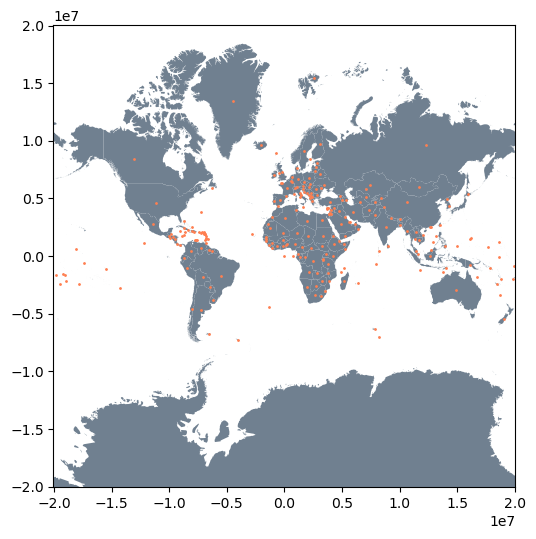

In [9]:
# Visualizando el resultado - Observa la diferencia con respecto al mapa anterior
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
paises_mercator.plot(ax=ax, color="slategray", edgecolor=None)
puntos_internos.plot(ax=ax, color="coral", markersize=1)
# Límites en EPSG:3857 (metros)
ax.set_xlim(-20037508, 20037508)   # eje X
ax.set_ylim(-20037508, 20037508)   # eje Y
plt.show()

<br>
<br>

#### 2.2. Buffers multi-anillo

Vamos a refrescar de nuevo el epígrafe de cálculo de buffer en este tutorial. Uno de los mayores hándicaps del método <code>buffer</code> de <code>Shapely</code> en GeoPandas es que no permite hacer buffers multi-anillo como podemos hacer directamente con una herramienta implementada en un software SIG de escritorio. Esto es, calcular buffers con anillos concéntricos. Para solventar este problema en Python, debemos calcular múltiples buffers y luego calcular la diferencia con el método <code>difference</code> de GeoPandas, que hemos visto antes.

Veamos un ejemplo en el que calculamos varios buffers sobre la capa de puntos representativos de cada país. Vamos a crear un buffer de 100km y otro de 200km, y después calcularemos la diferencia entre ambos para obtener el polígono con el anillo entre 100 y 200km. Antes, vamos a comprobar el CRS y el tipo de objeto que representa "puntos_internos".

In [13]:
print(puntos_internos.crs)
print(puntos_internos.info())

EPSG:3857
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   admin     257 non-null    object  
 1   geometry  257 non-null    geometry
dtypes: geometry(1), object(1)
memory usage: 4.1+ KB
None


<br>
 Se trata de un geodataframe y su CRS es 3857 (Web Mercator), con unidades en "metros".

In [14]:
# Calcular buffer de 100 km (100.000 metros)
punto_buffer100 = puntos_internos.buffer(100000)

# Calcular buffer de 200 km (200.000 metros)
punto_buffer200 = puntos_internos.buffer(200000)

# Diferencia: Anillo 100-200 km
anillo_100_200 = punto_buffer200.difference(punto_buffer100)

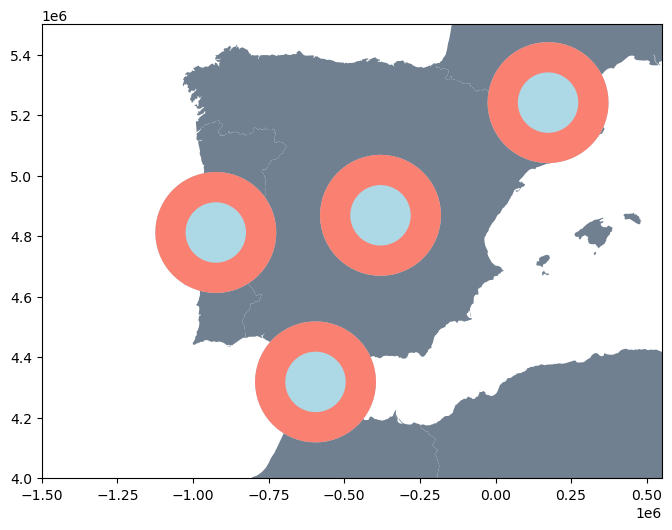

In [19]:
# Visualiza el resultado
fig, ax = plt.subplots(figsize=(8,6)) # Crear figura y eje
paises_mercator.plot(ax=ax, color="slategray", edgecolor=None) # Recuerda revisar el orden de las capas
punto_buffer200.plot(ax=ax, color="lightblue", edgecolor=None)
anillo_100_200.plot(ax=ax, color="salmon", edgecolor=None)

# Centrar visualización en la península Ibérica (EPSG:3857)
ax.set_xlim(-1500000, 550000)    # eje X (longitudes en metros)
ax.set_ylim(4000000, 5500000)    # eje Y (latitudes en metros)

plt.show()